# Skin Lesion Classification (DermaMNIST / HAM10000)

**This is a learning project, not a clinical model.** I want to be loud about that up front. No medical claims of any kind should be read out of this notebook.

The images are real dermatoscopic photos from HAM10000 (Tschandl et al., 2018, CC BY-NC 4.0), in the preprocessed DermaMNIST version from MedMNIST v2 (Yang et al., 2023): 10,015 images resized to 64x64, with the official train / val / test split (7,007 / 1,003 / 2,005). I download the `.npz` file straight from MedMNIST's Zenodo record, no account needed.

HAM10000 has 7 diagnostic classes. I collapse them into a binary task: malignant or pre-malignant (melanoma, basal cell carcinoma, actinic keratosis / intraepithelial carcinoma) vs benign (nevi, benign keratosis-like lesions, dermatofibroma, vascular lesions). About 19.5% of training images are in the malignant group.

What I'm showing: the end-to-end PyTorch pipeline (dataset class, small CNN, class-weighted training loop, evaluation) on real data.

In [1]:
import os, urllib.request
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
device = "cpu"
print("device:", device)

device: cpu


## Load DermaMNIST (64x64)

DermaMNIST label ids: 0 actinic keratoses / intraepithelial carcinoma, 1 basal cell carcinoma, 2 benign keratosis-like, 3 dermatofibroma, 4 melanoma, 5 melanocytic nevi, 6 vascular lesions.

train images: (7007, 64, 64, 3)  malignant share: 0.195
val   images: (1003, 64, 64, 3)  malignant share: 0.195
test  images: (2005, 64, 64, 3)  malignant share: 0.196


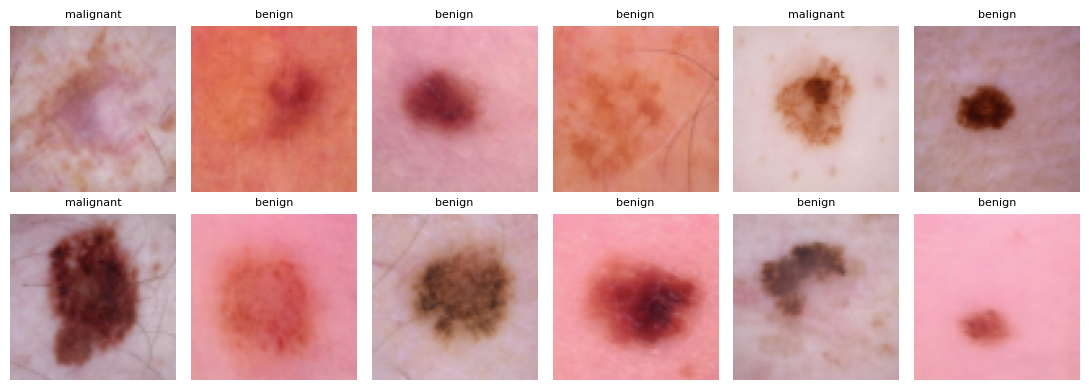

In [2]:
DATA = Path("../../data/medmnist")
NPZ = DATA / "dermamnist_64.npz"
if not NPZ.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://zenodo.org/records/10519652/files/dermamnist_64.npz?download=1", NPZ)
d = np.load(NPZ)
MALIGNANT = [0, 1, 4]   # akiec, bcc, melanoma
def binary(lbl): return np.isin(lbl.ravel(), MALIGNANT).astype(np.int64)
splits = {s: (d[f"{s}_images"], binary(d[f"{s}_labels"])) for s in ["train", "val", "test"]}
for s, (x, y) in splits.items():
    print(f"{s:5s} images: {x.shape}  malignant share: {y.mean():.3f}")

imgs, labels = splits["train"]
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i])
    ax.set_title("malignant" if labels[i] else "benign", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Dataset + small CNN

In [3]:
class LesionDataset(Dataset):
    def __init__(self, imgs, labels):
        self.x = torch.tensor(imgs.transpose(0, 3, 1, 2) / 255.0, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

train_ds = LesionDataset(*splits["train"])
test_ds = LesionDataset(*splits["test"])
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=256)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Linear(64, 2),
        )
    def forward(self, x): return self.net(x)

model = SmallCNN().to(device)
print(sum(p.numel() for p in model.parameters()), "params")

23714 params


## Train 8 epochs, class-weighted

The loss weights each class by the inverse of its training frequency, so the model can't just call everything benign. Evaluation is on the official 2,005-image test split.

In [4]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
counts = np.bincount(splits["train"][1])
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32))

for ep in range(8):
    model.train(); running = 0.0; n = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward(); opt.step()
        running += loss.item() * x.size(0); n += x.size(0)
    print(f"ep {ep+1}  train_loss={running/n:.3f}")

model.eval()
all_y, all_p, all_score = [], [], []
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        logits = model(x)
        score = F.softmax(logits, 1)[:, 1].cpu().numpy()
        all_y.extend(y.tolist())
        all_p.extend(logits.argmax(1).cpu().tolist())
        all_score.extend(score.tolist())

print("\nclassification report:")
print(classification_report(all_y, all_p, target_names=["benign", "malignant"], digits=3))
try:
    print(f"auc: {roc_auc_score(all_y, all_score):.3f}")
except ValueError:
    pass
print("confusion matrix:")
print(confusion_matrix(all_y, all_p))

ep 1  train_loss=0.637


ep 2  train_loss=0.577


ep 3  train_loss=0.570


ep 4  train_loss=0.554


ep 5  train_loss=0.555


ep 6  train_loss=0.542


ep 7  train_loss=0.547


ep 8  train_loss=0.544



classification report:
              precision    recall  f1-score   support

      benign      0.934     0.539     0.683      1613
   malignant      0.308     0.844     0.451       392

    accuracy                          0.599      2005
   macro avg      0.621     0.692     0.567      2005
weighted avg      0.812     0.599     0.638      2005

auc: 0.758
confusion matrix:
[[869 744]
 [ 61 331]]


## Results and disclaimer (repeating because it matters)

On the official 2,005-image test split the small CNN gets ROC-AUC 0.758. With class-weighted loss and the default 0.5 threshold it catches 84% of the malignant / pre-malignant lesions (331 of 392), but at the cost of flagging 744 of 1,613 benign lesions, so only 31% of its "malignant" calls are right. The training loss flattened out around 0.54 after a few epochs, which says the model is too small (24K parameters, 64x64 inputs) rather than undertrained.

That's an honest baseline for a tiny from-scratch CNN, and it's nowhere near usable. Dermatologists look at fine texture and border detail that mostly disappears at 64x64.

If I were to do this for real:
- Use the full 7-way label space and higher resolution (MedMNIST also ships 128 and 224 pixel versions, or the original HAM10000 images).
- Use a pretrained backbone (EfficientNet-B0 or ConvNeXt-tiny) and fine-tune, instead of training from scratch.
- Report sensitivity per class with confidence intervals, not just overall accuracy. False negatives on melanoma cost a lot more than false positives.
- Split by patient (HAM10000 has several images of the same lesion), and test on images from a different clinic.
- Have a dermatologist look at the failure cases. *Then* maybe call it a model.